<div style="text-align:center; margin-top:60px">
<h2>BÁO CÁO THỰC HÀNH</h2>
<h1>KHAI PHÁ DỮ LIỆU</h1>
<h3>Áp dụng KNN, K-Means, Naive Bayes và Decision Tree<br>trên hai bộ dữ liệu UCI</h3>
<br>
<p><b>Dataset 1:</b> Predict Students' Dropout and Academic Success (UCI #697)<br>
<b>Dataset 2:</b> Individual Household Electric Power Consumption (UCI #235)</p>
<br>
<p><b>Sinh viên thực hiện:</b> Hoàng Văn Huynh<br>
<b>MSSV:</b> B23DCCC086</p>
<p><b>Ngày:</b> 08/10/2026</p>
</div>

## 1. Mục tiêu và quy trình thực hiện

Chọn 2 trong 4 dataset: **#697 Students' Dropout** (dữ liệu bảng, có sẵn nhãn 3 lớp) và **#235 Household Power** (2 triệu bản ghi chuỗi thời gian, nhiệm vụ gốc gồm phân cụm). Trên mỗi dataset: phân tích thống kê, áp dụng **KNN, Naive Bayes, Decision Tree** (phân lớp) và **K-Means** (phân cụm).

| Bước | Nội dung |
|---|---|
| 1. Thu thập | Tải dữ liệu gốc từ UCI Machine Learning Repository |
| 2. Thống kê mô tả | Kích thước, giá trị thiếu, mean / std / min / max / tứ phân vị, skewness, kurtosis, phân bố, tương quan |
| 3. Tiền xử lý | Xử lý thiếu, One-Hot biến danh mục, chuẩn hóa StandardScaler, tạo đặc trưng / nhãn, chia train–test |
| 4. Mô hình | KNN, Gaussian Naive Bayes, Decision Tree (GridSearchCV 5-fold, tiêu chí macro-F1); K-Means (k-means++) |
| 5. Đánh giá | Phân lớp: Accuracy, macro-F1, F1 từng lớp, ma trận nhầm lẫn. Phân cụm: Elbow, Silhouette, ARI / NMI |

- **KNN:** gán nhãn theo đa số *k* láng giềng gần nhất (khoảng cách Euclid) → cần chuẩn hóa.
- **Naive Bayes:** định lý Bayes, giả định các đặc trưng độc lập và phân phối chuẩn trong mỗi lớp.
- **Decision Tree:** chia dữ liệu theo ngưỡng làm giảm Gini nhiều nhất; dễ diễn giải.
- **K-Means:** chia K cụm, cực tiểu tổng bình phương khoảng cách tới tâm cụm; lặp *gán điểm → cập nhật tâm*.

Dữ liệu mất cân bằng lớp nên mô hình được chọn theo **macro-F1** (trung bình F1 các lớp).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score)

pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3, 'axes.axisbelow': True})
SEED = 42
COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3', '#937860']
short = lambda c: c.replace('Curricular units ', 'CU ')

def save(name):
    plt.tight_layout(); plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

def stats_table(df):
    # describe + skewness + kurtosis + số giá trị thiếu
    t = df.describe().T
    t['skew'] = df.skew(); t['kurtosis'] = df.kurtosis(); t['missing'] = df.isna().sum()
    return t.rename(columns={'count': 'n', '50%': 'median'}, index=short)

MODELS = {
    'KNN': (KNeighborsClassifier(),
            {'clf__n_neighbors': list(range(1, 32, 2)), 'clf__weights': ['uniform', 'distance']}),
    'Naive Bayes': (GaussianNB(), {'clf__var_smoothing': np.logspace(-12, 0, 13)}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED),
                      {'clf__max_depth': [2, 3, 4, 5, 6, 8, 10, 15, None],
                       'clf__min_samples_leaf': [1, 5, 10, 20, 50]}),
}

def classify(pre, X_tr, y_tr, X_te, y_te, cv, labels, tag):
    # Huấn luyện 3 mô hình, in bảng kết quả, vẽ đường k của KNN, ma trận nhầm lẫn và biểu đồ so sánh
    fits, rows, preds = {}, [], {}
    for name, (clf, grid) in MODELS.items():
        gs = GridSearchCV(Pipeline([('pre', pre), ('clf', clf)]), grid, cv=cv,
                          scoring='f1_macro', n_jobs=-1).fit(X_tr, y_tr)
        p = preds[name] = gs.predict(X_te); fits[name] = gs
        best = {k.replace('clf__', ''): (float(f'{v:.0e}') if isinstance(v, float) else v)
                for k, v in gs.best_params_.items()}
        rows.append({'Mô hình': name, 'Tham số tốt nhất': str(best), 'CV macro-F1': gs.best_score_,
                     'Accuracy': accuracy_score(y_te, p), 'macro-F1': f1_score(y_te, p, average='macro'),
                     **{f'F1 {l}': v for l, v in zip(labels, f1_score(y_te, p, labels=labels, average=None))}})
    res = pd.DataFrame(rows).set_index('Mô hình')

    r = pd.DataFrame(fits['KNN'].cv_results_)
    fig, ax = plt.subplots(figsize=(7, 3))
    for w, c in zip(['uniform', 'distance'], COLORS):
        s = r[r.param_clf__weights == w]
        ax.plot(s.param_clf__n_neighbors, s.mean_test_score, 'o-', ms=4, color=c, label=f'weights={w}')
    ax.set_xlabel('k'); ax.set_ylabel('CV macro-F1'); ax.legend(); ax.set_title('KNN – chọn k bằng 5-fold CV')
    save(f'{tag}_knn_k')

    display(Markdown('**Kết quả trên tập test** (tham số chọn bằng GridSearchCV trên tập train)')); display(res)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
    for ax, (name, p) in zip(axes, preds.items()):
        ConfusionMatrixDisplay(confusion_matrix(y_te, p, labels=labels), display_labels=labels).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.set_title(name); ax.grid(False)
    fig.suptitle('Ma trận nhầm lẫn trên tập test', y=1.02); save(f'{tag}_cm')
    return fits, res

def importance(gs, names, tag, top=10):
    imp = pd.Series(gs.best_estimator_['clf'].feature_importances_, index=names).sort_values().tail(top)
    fig, ax = plt.subplots(figsize=(7, .32 * len(imp) + .8)); ax.barh(imp.index, imp.values, color=COLORS[2])
    ax.set_title('Decision Tree – độ quan trọng đặc trưng (Gini)'); save(f'{tag}_tree_importance')

def kmeans_scan(X, tag, ks=range(2, 11)):
    rows = []
    for k in ks:
        km = KMeans(k, init='k-means++', n_init=10, random_state=SEED).fit(X)
        rows.append({'k': k, 'Inertia': km.inertia_, 'Silhouette': silhouette_score(X, km.labels_)})
    r = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(r.k, r.Inertia, 'o-', color=COLORS[0]); axes[0].set_title('Elbow (Inertia)'); axes[0].set_xlabel('k')
    axes[1].plot(r.k, r.Silhouette, 'o-', color=COLORS[1]); axes[1].set_title('Silhouette'); axes[1].set_xlabel('k')
    save(f'{tag}_kmeans_elbow'); display(r.set_index('k').T)

# 2. Dataset 1 – Students' Dropout and Academic Success (UCI #697)

## 2.1 Dữ liệu và thống kê mô tả

4.424 sinh viên một trường đại học Bồ Đào Nha, 36 đặc trưng (nhân khẩu học, tuyển sinh, tài chính, kết quả học tập HK1–HK2, kinh tế vĩ mô) và nhãn `Target`: **Dropout / Enrolled / Graduate**. Nhiều cột số nguyên thực chất là **mã danh mục** (Course, nghề nghiệp cha mẹ…).

Kích thước: 4,424 dòng × 37 cột | Giá trị thiếu: 0 | Dòng trùng: 0


**Thống kê mô tả các biến số chính**

,n,mean,std,min,25%,median,75%,max,skew,kurtosis,missing
Admission grade,"4,424.000",126.978,14.482,95.000,117.900,126.100,134.800,190.000,0.531,0.663,0
Previous qualification (grade),"4,424.000",132.613,13.188,95.000,125.000,133.100,140.000,190.000,0.313,0.968,0
Age at enrollment,"4,424.000",23.265,7.588,17.000,19.000,20.000,25.000,70.000,2.055,4.127,0
CU 1st sem (credited),"4,424.000",0.710,2.361,0.000,0.000,0.000,0.000,20.000,4.169,19.206,0
CU 1st sem (approved),"4,424.000",4.707,3.094,0.000,3.000,5.000,6.000,26.000,0.766,3.097,0
CU 1st sem (grade),"4,424.000",10.641,4.844,0.000,11.000,12.286,13.400,18.875,-1.568,0.908,0
CU 2nd sem (approved),"4,424.000",4.436,3.015,0.000,2.000,5.000,6.000,20.000,0.306,0.845,0
CU 2nd sem (grade),"4,424.000",10.230,5.211,0.000,10.750,12.200,13.333,18.571,-1.314,0.067,0
Unemployment rate,"4,424.000",11.566,2.664,7.600,9.400,11.100,13.900,16.200,0.212,-0.996,0


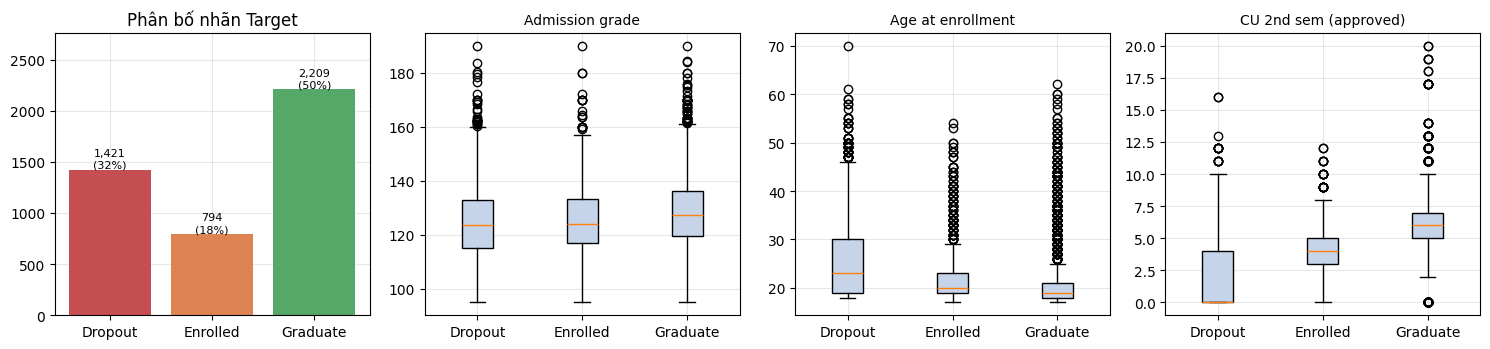

**Trung bình theo lớp và tương quan với Target** (Dropout=0, Enrolled=1, Graduate=2)

Target,Dropout,Enrolled,Graduate,r với Target
CU 2nd sem (approved),1.940,4.058,6.177,0.624
CU 2nd sem (grade),5.899,11.117,12.697,0.567
CU 1st sem (approved),2.552,4.319,6.232,0.529
CU 1st sem (grade),7.257,11.125,12.644,0.485
Tuition fees up to date,0.678,0.947,0.987,0.410
Scholarship holder,0.094,0.164,0.378,0.298
Age at enrollment,26.069,22.369,21.784,-0.243
Debtor,0.220,0.113,0.046,-0.241


In [2]:
df = pd.read_csv('data/697/data.csv', encoding='utf-8-sig'); df.columns = df.columns.str.strip()
print(f'Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột | Giá trị thiếu: {df.isna().sum().sum()} | '
      f'Dòng trùng: {df.duplicated().sum()}')
CAT_A = ['Marital Status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
         "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BIN_A = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
         'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
NUM_A = [c for c in df.columns if c not in CAT_A + BIN_A + ['Target']]
SHOW_A = ['Admission grade', 'Previous qualification (grade)', 'Age at enrollment',
          'Curricular units 1st sem (credited)', 'Curricular units 1st sem (approved)',
          'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (approved)',
          'Curricular units 2nd sem (grade)', 'Unemployment rate']
display(Markdown('**Thống kê mô tả các biến số chính**'))
display(stats_table(df[SHOW_A]))

order = ['Dropout', 'Enrolled', 'Graduate']; cmap = {'Dropout': COLORS[3], 'Enrolled': COLORS[1], 'Graduate': COLORS[2]}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
tc = df.Target.value_counts()[order]
b = axes[0].bar(tc.index, tc.values, color=[cmap[t] for t in order])
axes[0].bar_label(b, labels=[f'{v:,}\n({v / len(df):.0%})' for v in tc.values], fontsize=8)
axes[0].set_title('Phân bố nhãn Target'); axes[0].set_ylim(0, tc.max() * 1.25)
for ax, c in zip(axes[1:], ['Admission grade', 'Age at enrollment', 'Curricular units 2nd sem (approved)']):
    ax.boxplot([df.loc[df.Target == t, c] for t in order], labels=order, patch_artist=True,
               boxprops=dict(facecolor='#c6d4ea'))
    ax.set_title(short(c), fontsize=10)
save('A_eda')

display(Markdown('**Trung bình theo lớp và tương quan với Target** (Dropout=0, Enrolled=1, Graduate=2)'))
tmp = df[NUM_A + BIN_A].assign(Target_code=df.Target.map({'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}))
r = tmp.corr()['Target_code'].drop('Target_code'); top = r.abs().sort_values(ascending=False).index[:8]
t = df.groupby('Target')[list(top)].mean().T; t['r với Target'] = r[top]
display(t.rename(index=short))

**Nhận xét:** dữ liệu sạch (không thiếu, không trùng). Nhãn **mất cân bằng**: Graduate 50%, Dropout 32%, Enrolled chỉ 18%. Tuổi nhập học lệch phải mạnh (skew 2,06; median 20, max 70); điểm HK1/HK2 lệch trái (median ≈ 12,2 nhưng mean ≈ 10,4) do một khối sinh viên điểm 0; các biến *credited* hầu hết bằng 0 (kurtosis ≈ 19). Biến liên quan mạnh nhất tới Target là **số học phần đạt HK2** (r = 0,62; Dropout TB 1,9 so với Graduate 6,2), điểm HK2, số học phần đạt HK1 và **đóng học phí đúng hạn** (r = 0,41). Điểm đầu vào khác biệt ít giữa các lớp. Lớp Enrolled nằm giữa hai lớp kia ở hầu hết các biến → khó phân loại nhất.

## 2.2 Tiền xử lý

- **One-Hot** 9 biến mã danh mục; **StandardScaler** các biến số và nhị phân còn lại (đặt trong `Pipeline` để tránh rò rỉ dữ liệu).
- Chia **80% train / 20% test, stratified** theo Target (theo khuyến nghị của tác giả dataset).
- Tìm siêu tham số bằng GridSearchCV, StratifiedKFold 5-fold, tiêu chí macro-F1.

In [3]:
X, y = df.drop(columns='Target'), df.Target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
pre_A = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_A),
                           ('num', StandardScaler(), NUM_A + BIN_A)])
print(f'Train: {len(X_tr):,} mẫu | Test: {len(X_te):,} mẫu | '
      f'Số đặc trưng sau One-Hot: {pre_A.fit(X_tr).transform(X_tr[:1]).shape[1]}')

Train: 3,539 mẫu | Test: 885 mẫu | Số đặc trưng sau One-Hot: 236


## 2.3 Phân lớp: KNN, Naive Bayes, Decision Tree

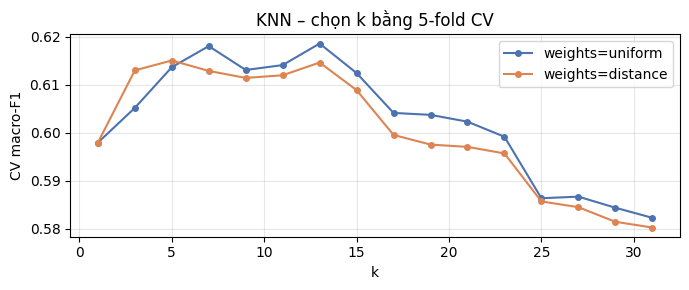

**Kết quả trên tập test** (tham số chọn bằng GridSearchCV trên tập train)

,Tham số tốt nhất,CV macro-F1,Accuracy,macro-F1,F1 Dropout,F1 Enrolled,F1 Graduate
Mô hình,,,,,,,
KNN,"{'n_neighbors': 13, 'weights': 'uniform'}",0.619,0.720,0.621,0.724,0.324,0.814
Naive Bayes,{'var_smoothing': 0.1},0.622,0.689,0.614,0.701,0.346,0.794
Decision Tree,"{'max_depth': 8, 'min_samples_leaf': 50}",0.676,0.745,0.655,0.746,0.378,0.840


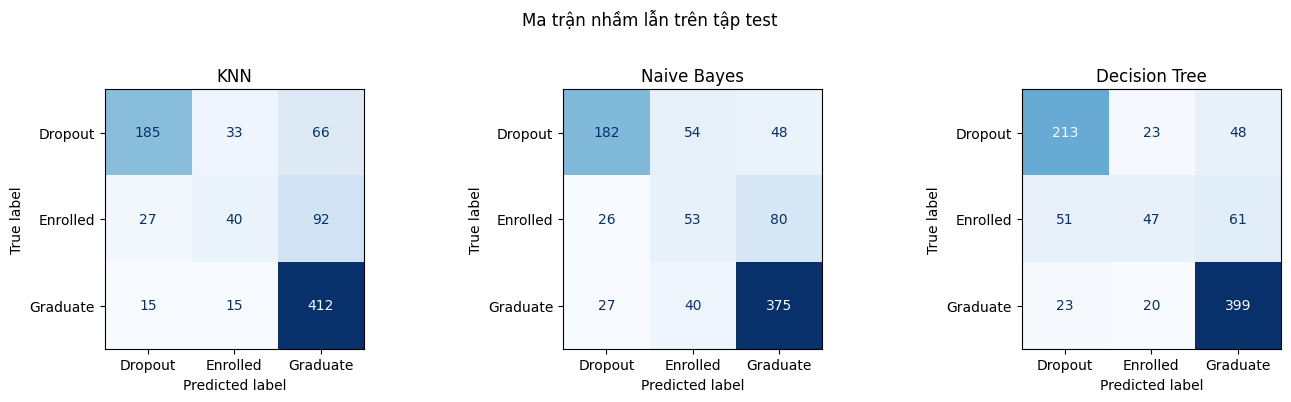

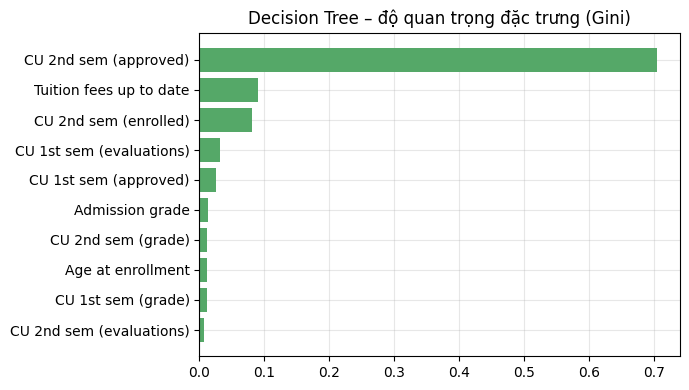

In [4]:
fits_A, res_A = classify(pre_A, X_tr, y_tr, X_te, y_te, StratifiedKFold(5, shuffle=True, random_state=SEED),
                         ['Dropout', 'Enrolled', 'Graduate'], 'A')
importance(fits_A['Decision Tree'], [short(n.split('__')[1]) for n in
           fits_A['Decision Tree'].best_estimator_['pre'].get_feature_names_out()], 'A')

**Nhận xét:**
- **Decision Tree tốt nhất** (accuracy 0,745; macro-F1 0,655; depth 8, lá ≥ 50 mẫu chống overfitting). Đặc trưng quan trọng nhất là số học phần đạt HK2 (≈ 70%), sau đó là đóng học phí đúng hạn và số học phần đăng ký HK2.
- **KNN** (k = 13): accuracy 0,720; macro-F1 0,621. F1 thấp tại k = 1, cao nhất ở k ≈ 7–13 rồi giảm khi k quá lớn. 236 chiều sau One-Hot làm khoảng cách kém phân biệt.
- **Naive Bayes** kém nhất (accuracy 0,689; macro-F1 0,614) vì các biến HK1–HK2 tương quan mạnh, vi phạm giả định độc lập. Cần `var_smoothing` = 0,1 do các cột One-Hot gần như hằng số trong từng lớp.
- Cả ba mô hình đều yếu ở lớp **Enrolled** (F1 0,32–0,38), lớp thiểu số nằm giữa Dropout và Graduate.

## 2.4 Phân cụm K-Means

Chỉ dùng 15 biến số có ý nghĩa khoảng cách (điểm đầu vào, tuổi, 12 biến kết quả học tập HK1–HK2), chuẩn hóa z-score; **không dùng nhãn**. Nhãn chỉ dùng sau để đánh giá (ARI, NMI).

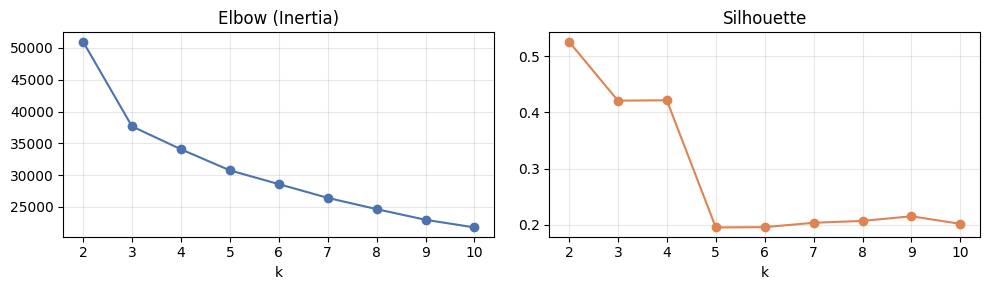

k,2,3,4,5,6,7,8,9,10
Inertia,"50,984.161","37,671.125","34,071.115","30,758.842","28,594.553","26,434.314","24,664.035","22,988.083","21,789.082"
Silhouette,0.526,0.421,0.421,0.196,0.196,0.204,0.207,0.215,0.202


K = 3: Silhouette = 0.421 | ARI = 0.145 | NMI = 0.154


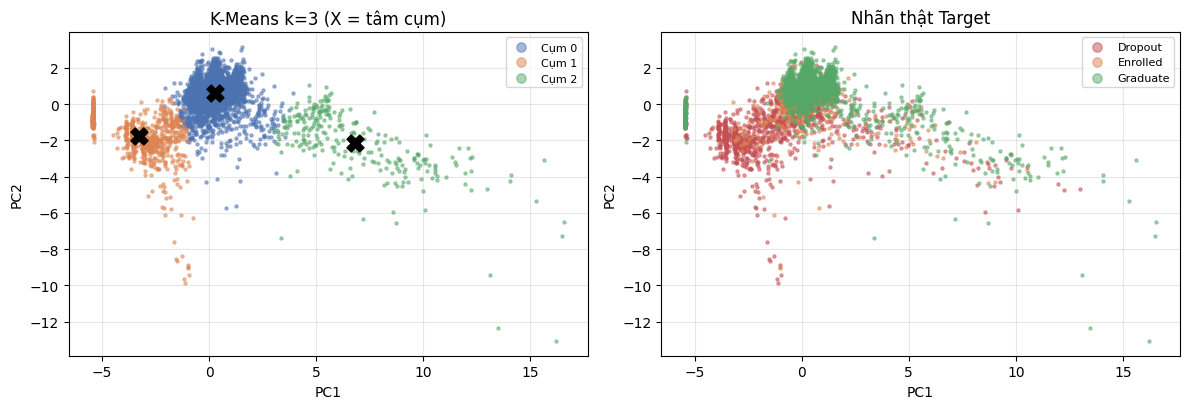

**Đặc điểm từng cụm (trung bình) và tỉ lệ % Target trong cụm**

,Age at enrollment,CU 1st sem (credited),CU 2nd sem (enrolled),CU 2nd sem (approved),CU 2nd sem (grade),Dropout (%),Enrolled (%),Graduate (%),Số SV
Cụm,,,,,,,,,
0,22.182,0.230,6.257,5.074,12.462,20.421,20.571,59.008,3325
1,25.845,0.022,4.397,0.077,0.537,81.993,8.884,9.124,833
2,28.722,8.865,11.662,10.113,12.687,22.180,13.534,64.286,266


In [5]:
KM_A = ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment'] + \
       [c for c in df.columns if c.startswith('Curricular')]
Z_A = StandardScaler().fit_transform(df[KM_A]); kmeans_scan(Z_A, 'A')

km = KMeans(3, init='k-means++', n_init=10, random_state=SEED).fit(Z_A); cl = pd.Series(km.labels_, name='Cụm')
print(f'K = 3: Silhouette = {silhouette_score(Z_A, cl):.3f} | ARI = {adjusted_rand_score(df.Target, cl):.3f} | '
      f'NMI = {normalized_mutual_info_score(df.Target, cl):.3f}')
pc = PCA(2, random_state=SEED).fit(Z_A); P = pc.transform(Z_A); C = pc.transform(km.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for k in range(3):
    axes[0].scatter(*P[cl == k].T, s=5, alpha=.5, color=COLORS[k], label=f'Cụm {k}')
axes[0].scatter(*C.T, marker='X', s=150, c='black'); axes[0].set_title('K-Means k=3 (X = tâm cụm)')
for t in ['Dropout', 'Enrolled', 'Graduate']:
    axes[1].scatter(*P[df.Target == t].T, s=5, alpha=.5, color=cmap[t], label=t)
axes[1].set_title('Nhãn thật Target')
for ax in axes:
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(markerscale=3, fontsize=8)
save('A_kmeans_pca')

prof = df[['Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 2nd sem (enrolled)',
           'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)']].groupby(cl).mean()
ct = pd.crosstab(cl, df.Target, normalize='index') * 100
display(Markdown('**Đặc điểm từng cụm (trung bình) và tỉ lệ % Target trong cụm**'))
display(pd.concat([prof.rename(columns=short), ct.add_suffix(' (%)')], axis=1).assign(**{'Số SV': cl.value_counts().sort_index()}))

**Nhận xét:** Elbow gãy rõ tại k = 3, silhouette 0,421 → chọn **k = 3**. K-Means *tự tìm ra* nhóm **thất bại học tập** (cụm 1, 833 SV: gần như không đạt học phần nào, **82% là Dropout**), nhóm **học bình thường** (cụm 0, 3.325 SV, 59% Graduate) và nhóm **chuyển tiếp / văn bằng 2** (cụm 2, 266 SV: nhiều học phần được công nhận, tuổi TB 28,7). Tuy vậy ARI = 0,145 thấp: cụm 0 trộn lẫn cả 3 lớp, Enrolled không tách thành cụm riêng → K-Means hữu ích để khám phá nhưng không thay được mô hình phân lớp.

# 3. Dataset 2 – Individual Household Electric Power Consumption (UCI #235)

## 3.1 Dữ liệu và thống kê mô tả

Điện năng của một hộ gia đình ở Sceaux (Pháp), **mỗi phút một bản ghi** từ 12/2006 đến 11/2010. Biến: Global_active_power (GAP, kW), Global_reactive_power (kW), Voltage (V), Global_intensity (A), Sub_metering_1/2/3 (Wh: bếp / giặt / nóng lạnh + điều hòa). Tạo thêm `Sub_metering_rest = GAP×1000/60 − S1 − S2 − S3` (thiết bị khác). Dataset **không có nhãn**.

Kích thước: 2,075,259 dòng × 7 biến | 16/12/2006 → 26/11/2010
Dòng thiếu giá trị: 25,979 (1.25%), nằm trong 82 ngày


**Thống kê mô tả (dữ liệu theo phút)**

,n,mean,std,min,25%,median,75%,max,skew,kurtosis,missing
Global_active_power,"2,049,280.000",1.092,1.057,0.076,0.308,0.602,1.528,11.122,1.786,4.219,25979
Global_reactive_power,"2,049,280.000",0.124,0.113,0.000,0.048,0.100,0.194,1.390,1.262,2.606,25979
Voltage,"2,049,280.000",240.840,3.240,223.200,238.990,241.010,242.890,254.150,-0.327,0.725,25979
Global_intensity,"2,049,280.000",4.628,4.444,0.200,1.400,2.600,6.400,48.400,1.849,4.601,25979
Sub_metering_1,"2,049,280.000",1.122,6.153,0.000,0.000,0.000,0.000,88.000,5.945,35.643,25979
Sub_metering_2,"2,049,280.000",1.299,5.822,0.000,0.000,0.000,1.000,80.000,7.091,57.907,25979
Sub_metering_3,"2,049,280.000",6.458,8.437,0.000,0.000,1.000,17.000,31.000,0.725,-1.282,25979
Sub_metering_rest,"2,049,280.000",9.315,9.586,-2.400,3.800,5.500,10.367,124.833,2.487,7.911,25979


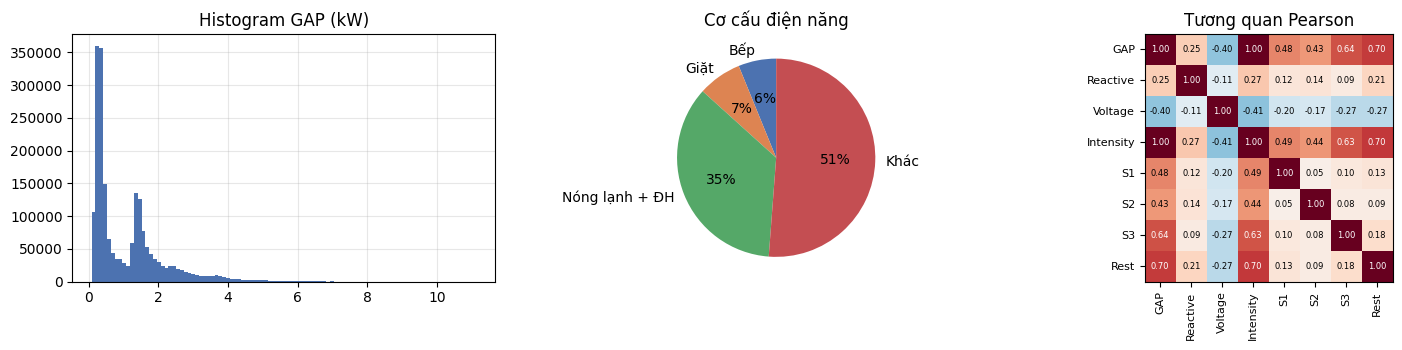

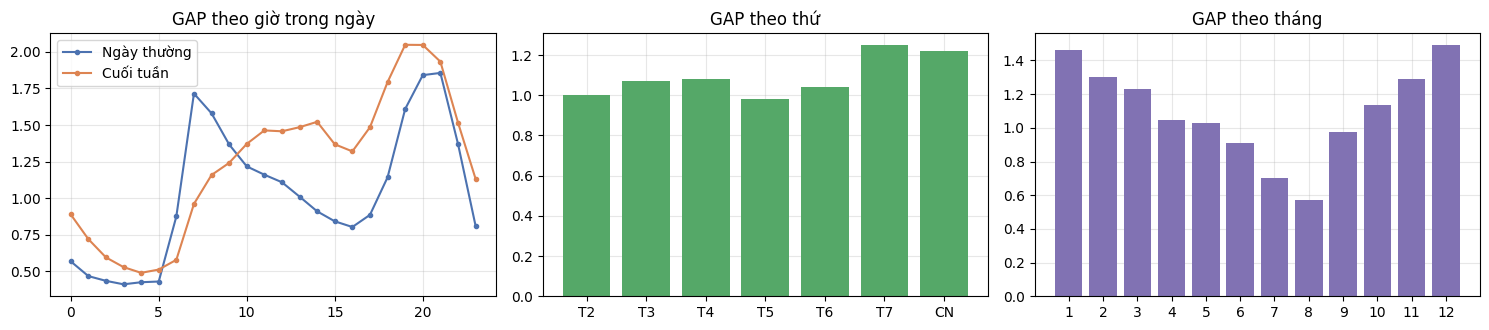

In [6]:
pw = pd.read_csv('data/235/household_power_consumption.txt', sep=';', na_values='?', low_memory=False)
pw.index = pd.to_datetime(pw.pop('Date') + ' ' + pw.pop('Time'), format='%d/%m/%Y %H:%M:%S')
pw = pw.astype('float64'); miss = pw.isna().any(axis=1)
print(f'Kích thước: {pw.shape[0]:,} dòng × {pw.shape[1]} biến | {pw.index.min():%d/%m/%Y} → {pw.index.max():%d/%m/%Y}')
print(f'Dòng thiếu giá trị: {miss.sum():,} ({miss.mean():.2%}), nằm trong {pw.index[miss].normalize().nunique()} ngày')
pw['Sub_metering_rest'] = pw.Global_active_power * 1000 / 60 - pw[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].sum(axis=1, min_count=3)
display(Markdown('**Thống kê mô tả (dữ liệu theo phút)**')); display(stats_table(pw))

gap = pw.Global_active_power
energy = pw[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Sub_metering_rest']].sum()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(gap.dropna(), bins=100, color=COLORS[0]); axes[0].set_title('Histogram GAP (kW)')
axes[1].pie(energy, labels=['Bếp', 'Giặt', 'Nóng lạnh + ĐH', 'Khác'], autopct='%1.0f%%', colors=COLORS[:4], startangle=90)
axes[1].set_title('Cơ cấu điện năng')
c = pw.corr(); im = axes[2].imshow(c, cmap='RdBu_r', vmin=-1, vmax=1)
lab = ['GAP', 'Reactive', 'Voltage', 'Intensity', 'S1', 'S2', 'S3', 'Rest']
axes[2].set_xticks(range(8)); axes[2].set_xticklabels(lab, rotation=90, fontsize=8)
axes[2].set_yticks(range(8)); axes[2].set_yticklabels(lab, fontsize=8); axes[2].grid(False)
for i in range(8):
    for j in range(8):
        axes[2].text(j, i, f'{c.iat[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if abs(c.iat[i, j]) > .6 else 'black')
axes[2].set_title('Tương quan Pearson'); save('B_eda')

days = ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for wk, lab, col in [(False, 'Ngày thường', COLORS[0]), (True, 'Cuối tuần', COLORS[1])]:
    s = gap[(gap.index.dayofweek >= 5) == wk]; axes[0].plot(s.groupby(s.index.hour).mean(), 'o-', ms=3, color=col, label=lab)
axes[0].set_title('GAP theo giờ trong ngày'); axes[0].legend()
axes[1].bar(days, gap.groupby(gap.index.dayofweek).mean(), color=COLORS[2]); axes[1].set_title('GAP theo thứ')
axes[2].bar(range(1, 13), gap.groupby(gap.index.month).mean(), color=COLORS[4]); axes[2].set_title('GAP theo tháng')
axes[2].set_xticks(range(1, 13)); save('B_profiles')

**Nhận xét:** 1,25% số dòng bị thiếu, tập trung thành khối nhiều ngày liền. GAP **lệch phải** (mean 1,09 > median 0,60 kW; skew 1,79) và có **hai đỉnh** (≈ 0,3 kW tải nền, ≈ 1,4 kW khi có thiết bị lớn). Nóng lạnh + điều hòa chiếm 36% điện năng; thiết bị không đo riêng chiếm 51%. **Global_intensity tương quan r = 1,00 với GAP** (P ≈ U·I) → trùng thông tin; Voltage tương quan âm (−0,40) do sụt áp khi tải lớn. Tiêu thụ có **tính chu kỳ** rõ: ngày thường có đỉnh 7h và 20–21h, cuối tuần tải cao cả ngày; cao vào mùa đông (tháng 12: 1,48 kW), thấp nhất tháng 8 (0,57 kW).

## 3.2 Tiền xử lý và tạo bài toán phân lớp

- Bỏ các phút thiếu, **gộp theo giờ** (≈ 34 nghìn bản ghi) để giảm nhiễu và giúp KNN khả thi.
- **Nhãn** `Mức tải` của mỗi giờ: Thấp / Trung bình / Cao theo tam phân vị GAP, tính trên tập train.
- **Đặc trưng:** hour, dayofweek, month, is_weekend, Voltage, Global_reactive_power, `lag1` (GAP giờ trước). **Loại** Global_intensity và Sub_metering cùng giờ vì gần như suy ra trực tiếp nhãn (rò rỉ).
- **Chia theo thời gian:** 80% đầu train, 20% cuối test; CV bằng `TimeSeriesSplit`.

In [7]:
H = pw.drop(columns='Sub_metering_rest').resample('h').mean()
H['lag1'] = H.Global_active_power.shift(1); H = H.dropna()
H['hour'], H['dayofweek'], H['month'] = H.index.hour, H.index.dayofweek, H.index.month
H['is_weekend'] = (H.dayofweek >= 5).astype(int)
cut = int(len(H) * .8); q1, q2 = H.Global_active_power.iloc[:cut].quantile([1 / 3, 2 / 3])
LAB_B = ['Thấp', 'Trung bình', 'Cao']
H['Mức tải'] = pd.cut(H.Global_active_power, [-np.inf, q1, q2, np.inf], labels=LAB_B).astype(str)
FEAT_B = ['hour', 'dayofweek', 'month', 'is_weekend', 'Voltage', 'Global_reactive_power', 'lag1']
Xb_tr, Xb_te, yb_tr, yb_te = H[FEAT_B].iloc[:cut], H[FEAT_B].iloc[cut:], H['Mức tải'].iloc[:cut], H['Mức tải'].iloc[cut:]
print(f'Số giờ: {len(H):,} | Ngưỡng: Thấp ≤ {q1:.3f} kW < Trung bình ≤ {q2:.3f} kW < Cao')
print(f'Train: {Xb_tr.index.min():%d/%m/%Y} → {Xb_tr.index.max():%d/%m/%Y} ({len(Xb_tr):,} giờ) | '
      f'Test: {Xb_te.index.min():%d/%m/%Y} → {Xb_te.index.max():%d/%m/%Y} ({len(Xb_te):,} giờ)')
display(pd.DataFrame({'Train (%)': yb_tr.value_counts(normalize=True) * 100,
                      'Test (%)': yb_te.value_counts(normalize=True) * 100}).loc[LAB_B].T)

Số giờ: 34,159 | Ngưỡng: Thấp ≤ 0.396 kW < Trung bình ≤ 1.395 kW < Cao
Train: 16/12/2006 → 05/02/2010 (27,327 giờ) | Test: 05/02/2010 → 26/11/2010 (6,832 giờ)


Mức tải,Thấp,Trung bình,Cao
Train (%),33.333,33.333,33.333
Test (%),28.908,40.354,30.738


## 3.3 Phân lớp: KNN, Naive Bayes, Decision Tree

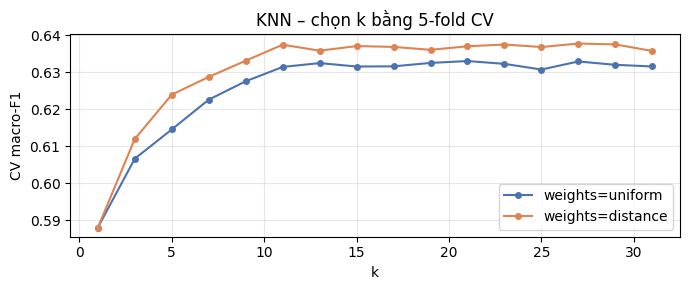

**Kết quả trên tập test** (tham số chọn bằng GridSearchCV trên tập train)

,Tham số tốt nhất,CV macro-F1,Accuracy,macro-F1,F1 Thấp,F1 Trung bình,F1 Cao
Mô hình,,,,,,,
KNN,"{'n_neighbors': 27, 'weights': 'distance'}",0.638,0.635,0.642,0.692,0.515,0.719
Naive Bayes,{'var_smoothing': 0.0001},0.596,0.572,0.575,0.667,0.446,0.614
Decision Tree,"{'max_depth': 8, 'min_samples_leaf': 10}",0.693,0.668,0.675,0.685,0.595,0.744


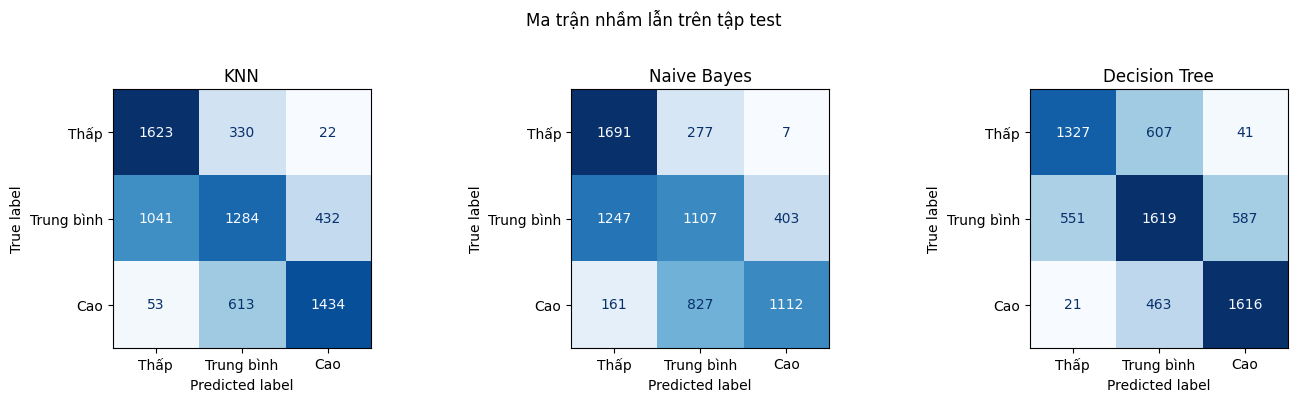

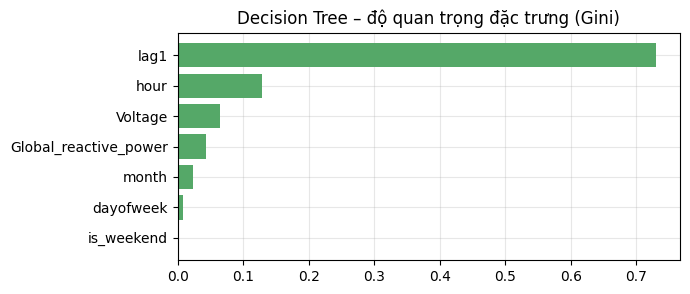

In [8]:
fits_B, res_B = classify(StandardScaler(), Xb_tr, yb_tr, Xb_te, yb_te, TimeSeriesSplit(5), LAB_B, 'B')
importance(fits_B['Decision Tree'], FEAT_B, 'B')

**Nhận xét:**
- **Decision Tree tốt nhất** (accuracy 0,668; macro-F1 0,675). `lag1` chiếm ≈ 73% độ quan trọng (quán tính của phụ tải), sau đó là `hour` (≈ 13%).
- **KNN** (k = 27, weights = distance): accuracy 0,635; macro-F1 0,642. k lớn vì dữ liệu nhiễu.
- **Naive Bayes** kém nhất (accuracy 0,572): `lag1` lệch phải, không phân phối chuẩn; quan hệ của `hour` với tải không đơn điệu (hai đỉnh sáng/tối).
- Lớp **Trung bình** khó nhất. Điểm thấp hơn #697 vì nhãn tạo bằng ngưỡng cứng và tập test (02–11/2010) **lệch mùa** so với train (Trung bình chiếm 40%). Kết quả vẫn **gấp đôi đoán ngẫu nhiên** (0,33).

## 3.4 Phân cụm K-Means – các kiểu ngày tiêu thụ điện

Mỗi **ngày** là một vector 24 chiều (GAP trung bình từng giờ); chỉ giữ ngày đủ 24 giờ. Không chuẩn hóa vì cùng đơn vị kW.

Số ngày đủ 24 giờ: 1,417


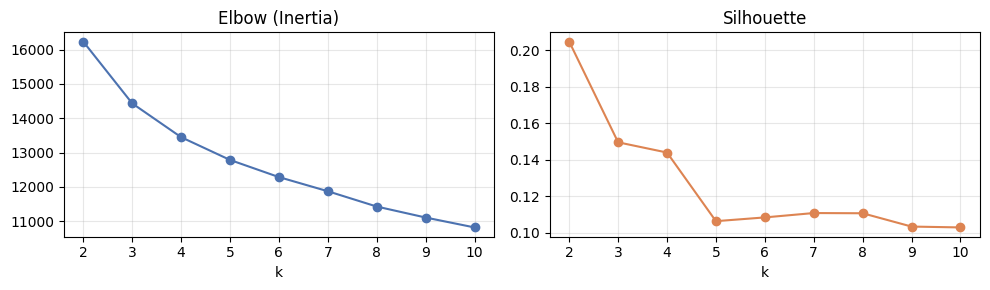

k,2,3,4,5,6,7,8,9,10
Inertia,"16,233.597","14,434.030","13,449.010","12,785.468","12,285.571","11,873.252","11,427.090","11,107.041","10,818.112"
Silhouette,0.205,0.150,0.144,0.106,0.108,0.111,0.111,0.103,0.103


K = 4: Silhouette = 0.144


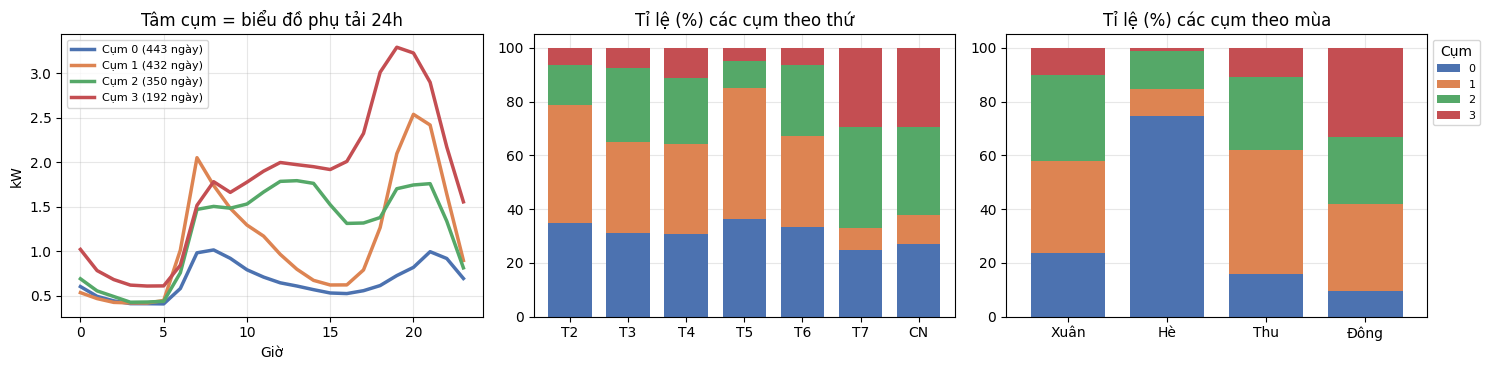

**Đặc điểm từng cụm**

,Số ngày,GAP TB (kW),GAP đỉnh (kW),Giờ đỉnh,kWh/ngày,% cuối tuần
0,443,0.665,1.015,8,15.962,23.476
1,432,1.116,2.540,20,26.791,8.796
2,350,1.237,1.794,13,29.678,40.000
3,192,1.756,3.295,19,42.150,61.458


In [9]:
D = H.Global_active_power.to_frame('gap').assign(date=H.index.normalize(), hour=H.index.hour) \
     .pivot_table(index='date', columns='hour', values='gap').dropna()
print(f'Số ngày đủ 24 giờ: {len(D):,}'); kmeans_scan(D.values, 'B')

K_B = 4
km = KMeans(K_B, init='k-means++', n_init=10, random_state=SEED).fit(D.values)
order = np.argsort(km.cluster_centers_.mean(axis=1)); remap = {o: n for n, o in enumerate(order)}
cl = pd.Series(km.labels_, index=D.index).map(remap); centers = km.cluster_centers_[order]
print(f'K = {K_B}: Silhouette = {silhouette_score(D.values, cl):.3f}')

season = cl.index.month.map({12: 'Đông', 1: 'Đông', 2: 'Đông', 3: 'Xuân', 4: 'Xuân', 5: 'Xuân',
                             6: 'Hè', 7: 'Hè', 8: 'Hè', 9: 'Thu', 10: 'Thu', 11: 'Thu'})
dow = np.array(days)[cl.index.dayofweek]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for k in range(K_B):
    axes[0].plot(centers[k], color=COLORS[k], lw=2.5, label=f'Cụm {k} ({(cl == k).sum()} ngày)')
axes[0].set_title('Tâm cụm = biểu đồ phụ tải 24h'); axes[0].set_xlabel('Giờ'); axes[0].set_ylabel('kW'); axes[0].legend(fontsize=8)
for ax, by, idx, title in [(axes[1], dow, days, 'thứ'), (axes[2], season, ['Xuân', 'Hè', 'Thu', 'Đông'], 'mùa')]:
    (pd.crosstab(np.asarray(by), cl.values, normalize='index') * 100).loc[idx].plot.bar(
        stacked=True, ax=ax, color=COLORS[:K_B], rot=0, width=.75, legend=False)
    ax.set_title(f'Tỉ lệ (%) các cụm theo {title}'); ax.set_xlabel('')
axes[2].legend(title='Cụm', fontsize=8, bbox_to_anchor=(1, 1)); save('B_kmeans')

display(Markdown('**Đặc điểm từng cụm**'))
display(pd.DataFrame({'Số ngày': cl.value_counts().sort_index(), 'GAP TB (kW)': centers.mean(axis=1),
                      'GAP đỉnh (kW)': centers.max(axis=1), 'Giờ đỉnh': centers.argmax(axis=1),
                      'kWh/ngày': centers.sum(axis=1),
                      '% cuối tuần': pd.Series(cl.index.dayofweek >= 5, index=cl.index).groupby(cl).mean() * 100}))

**Nhận xét:** không có khuỷu rõ, silhouette thấp (0,10–0,21) vì các kiểu ngày chuyển tiếp liên tục; chọn **k = 4** vì cho các cụm có ý nghĩa thực tế:

| Cụm | Kiểu ngày | Đặc điểm |
|---|---|---|
| 0 (443 ngày) | **Tải thấp** | Gần phẳng, ≈ 16 kWh/ngày; **75% số ngày mùa hè** (đi vắng, không sưởi) |
| 1 (432 ngày) | **Ngày đi làm** | Đỉnh sáng 7–8h và **tối 20h (2,5 kW)**; chỉ 9% là cuối tuần |
| 2 (350 ngày) | **Ở nhà ban ngày** | Tải đều 1,5–1,8 kW từ 7h–21h; 40% là cuối tuần |
| 3 (192 ngày) | **Tải cao** | Đỉnh 19h 3,3 kW, ≈ 42 kWh/ngày; 61% cuối tuần, chủ yếu mùa đông |

K-Means tự tìm ra lịch sinh hoạt (ngày thường / cuối tuần) và theo mùa dù đầu vào chỉ có 24 giá trị công suất.

# 4. Kết luận

| Dataset | KNN | Naive Bayes | Decision Tree | K-Means |
|---|---|---|---|---|
| #697 Dropout (Acc / macro-F1) | 0,720 / 0,621 | 0,689 / 0,614 | **0,745 / 0,655** | k=3; tìm ra cụm 82% Dropout; ARI 0,145 |
| #235 Điện năng (Acc / macro-F1) | 0,635 / 0,642 | 0,572 / 0,575 | **0,668 / 0,675** | k=4; 4 kiểu ngày tiêu thụ điện |

1. **Thống kê mô tả** định hướng cách làm: lệch lớp → dùng macro-F1; đa cộng tuyến và rò rỉ (Global_intensity) → loại biến; tính chu kỳ → đặc trưng thời gian và chia theo thời gian.
2. **Decision Tree** tốt nhất trên cả hai dataset nhờ học được quan hệ phi tuyến và cho luật dễ giải thích; **KNN** đứng thứ hai, cần chuẩn hóa và chọn k; **Naive Bayes** nhanh nhất nhưng kém nhất do giả định độc lập và phân phối chuẩn bị vi phạm.
3. **K-Means** hữu ích để khám phá nhóm (sinh viên thất bại học tập, kiểu ngày tiêu thụ) nhưng không thay thế được phân lớp; chọn k cần kết hợp Elbow, Silhouette và ý nghĩa thực tế.
4. **Hạn chế:** lớp Enrolled và lớp Trung bình còn yếu → có thể thử cân bằng lớp (`class_weight`, SMOTE) hoặc mô hình ensemble.

**Tài liệu tham khảo:** UCI Machine Learning Repository – dataset #697 (DOI 10.24432/C5MC89) và #235 (DOI 10.24432/C58K54); Martins et al. (2021), *Early prediction of student's performance in higher education*, Springer; scikit-learn documentation (scikit-learn.org).